# European City Recommendation — Fuzzy Multi-Criteria Model

This notebook develops a first mathematical and Python implementation based on the selected design:

- **Five fuzzy sets:** Very Low, Low, Medium, High, Very High.
- **Aggregation comparison:** weighted arithmetic mean versus weighted geometric mean.
- **Profile/trip balance:** 30% profile and 70% trip for topics present in both.
- **Hard constraints:** exclude destinations that violate strict constraints.

It uses the three artificial users from the questionnaire preprocessing example and the 50-city destination prototype.

> **Important data limitation:** the destination dataset currently contains synthetic placeholder scores and cost estimates. This notebook is a methodological prototype, not a source of valid real-world recommendations. Replace placeholder destination data with researched, consistently defined values before interpreting the rankings.

The model is modular: user preprocessing, destination matching, criterion weights, profile/trip balance, constraints and aggregation are separate steps.


## 1. Mathematical design

### 1.1 Five fuzzy sets

For a normalized value \(x\in[0,1]\), define five overlapping triangular membership functions with peaks at:

\[
c = (0,\;0.25,\;0.50,\;0.75,\;1)
\]

The end sets are shoulder functions. For an interior set with centre \(c_j\), left point \(a_j\), and right point \(b_j\):

\[
\mu_j(x)=\max\left(0,\min\left(\frac{x-a_j}{c_j-a_j},\frac{b_j-x}{b_j-c_j}\right)\right)
\]

For the first and last sets, use left/right shoulders so that membership covers the boundaries. The five memberships sum to 1 for this partition.

### 1.2 Similarity between user and destination

For a numerical criterion, fuzzify both the user's preference and the destination's suitability into five memberships. Compare the two fuzzy vectors using normalized L1 distance:

\[
C_i=1-\frac{1}{2}\sum_{j=1}^{5}|\mu_{U,ij}-\mu_{D,ij}|
\]

Thus \(C_i\in[0,1]\): 1 means identical fuzzy profiles; 0 means maximally different. This is a **fuzzy-set similarity measure**, not a full Mamdani/Sugeno rule base.

### 1.3 Profile and trip matching

For topics available in both questionnaires:

\[
C_i=0.30C_{P,i}+0.70C_{T,i}
\]

For profile-only topics, use the profile compatibility; for trip-only topics, use the trip compatibility. Do not manufacture a missing questionnaire answer.

### 1.4 Two aggregation methods to compare

**Weighted arithmetic mean (WAM):**

\[
S_{WAM}(d)=\frac{\sum_i w_i C_i(d)}{\sum_i w_i}
\]

This is compensatory: a high score on one criterion can offset a low score on another.

**Weighted geometric mean (WGM):**

\[
S_{WGM}(d)=\prod_i C_i(d)^{w_i/\sum w_i}
\]

This penalizes very low criterion scores more strongly. A small numerical epsilon is used only to avoid log(0).

Both return a score in [0,1]. They are alternative aggregation operators over criterion compatibility scores; comparing them is useful for sensitivity analysis.

### 1.5 Hard constraints

A strict maximum budget is applied before ranking:

\[
\text{eligible}(d)=\mathbb{1}[\text{estimated trip cost}(d)\leq\text{user maximum budget}]
\]

The prototype estimates trip cost as daily city cost × trip duration × number of travellers. This is only a placeholder calculation: a realistic model should define whether the city daily-cost estimate includes lodging, meals, local transport and activities, and how shared accommodation is handled.


## 2. Load the destination dataset

Place `european_city_destination_dataset_prototype.csv` in the same folder as this notebook. In Google Colab, upload the CSV when prompted.

The CSV has one row per city. Most destination attributes are 0–1 scores; climate and landscape are binary category indicators; daily cost is in EUR/day.


In [11]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_FILE = Path("european_city_destination_dataset_prototype.csv")

if not DATA_FILE.exists():
    # Colab upload fallback; in local Jupyter, put the CSV beside this notebook.
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("Upload the European city destination CSV.")
        DATA_FILE = Path(csv_names[0])
    except ImportError:
        raise FileNotFoundError(
            "Could not find the CSV. Put european_city_destination_dataset_prototype.csv "
            "in the same folder as this notebook."
        )

destinations = pd.read_csv(DATA_FILE)
print("Destinations:", len(destinations))
print("Columns:", len(destinations.columns))
display(destinations[["destination_id", "city", "country", "daily_cost_eur_estimate", "data_status"]].head())


Destinations: 50
Columns: 44


,destination_id,city,country,daily_cost_eur_estimate,data_status
0,EU001,Vienna,Austria,165,SYNTHETIC_PLACEHOLDER
1,EU002,Salzburg,Austria,155,SYNTHETIC_PLACEHOLDER
2,EU003,Brussels,Belgium,155,SYNTHETIC_PLACEHOLDER
3,EU004,Bruges,Belgium,145,SYNTHETIC_PLACEHOLDER
4,EU005,Dubrovnik,Croatia,175,SYNTHETIC_PLACEHOLDER


## 3. Artificial questionnaire respondents

The notebook includes the original three illustrative respondents (Alex, Blair and Casey) plus three additional profiles designed to test whether the recommendations respond sensibly to contrasting preferences:

- **Relaxation Seeker:** low activity, high relaxation, beaches and warm climate.
- **Adventurer:** high activity and novelty, mountains and forests, cooler climate.
- **Culture Enthusiast:** strong food and authenticity preferences, with interest in unique experiences and a more active city trip.

These are hypothetical test cases, not real participants. Their purpose is to probe the model's behaviour and identify surprising recommendations.

In [13]:
users = {
    "Alex": {
        "profile": {
            "food": 0.90, "authenticity": "Everyday local life",
            "relaxation": 0.30, "unique": 0.85, "landscape_importance": 0.90,
            "travel_pace": 0.83, "accommodation": 0.83,
            "physical_activity": 0.83, "price_sensitivity": 0.83,
            "safety_importance": 0.83, "eco_importance": 0.50
        },
        "trip": {
            "relaxation": 0.80, "unique": 0.83, "landscapes": ["Mountains", "Lakes"],
            "travel_pace": 0.17, "accommodation": 0.75,
            "physical_activity": 0.25, "climate": "Warm",
            "preferred_budget": 2000, "maximum_budget": 2500,
            "duration_days": 10, "travellers": 2
        }
    },
    "Blair": {
        "profile": {
            "food": 0.55, "authenticity": "Combination of both",
            "relaxation": 0.70, "unique": 0.45, "landscape_importance": 0.75,
            "travel_pace": 0.33, "accommodation": 1.00,
            "physical_activity": 0.17, "price_sensitivity": 0.50,
            "safety_importance": 1.00, "eco_importance": 0.50
        },
        "trip": {
            "relaxation": 0.65, "unique": 0.33, "landscapes": ["Countryside"],
            "travel_pace": 0.33, "accommodation": 1.00,
            "physical_activity": 0.25, "climate": "Mild",
            "preferred_budget": 1200, "maximum_budget": 1500,
            "duration_days": 7, "travellers": 1
        }
    },
    "Casey": {
        "profile": {
            "food": 0.75, "authenticity": "Tourist-oriented experiences",
            "relaxation": 0.15, "unique": 0.95, "landscape_importance": 0.60,
            "travel_pace": 1.00, "accommodation": 0.33,
            "physical_activity": 1.00, "price_sensitivity": 0.17,
            "safety_importance": 0.50, "eco_importance": 0.50
        },
        "trip": {
            "relaxation": 0.10, "unique": 1.00, "landscapes": ["Desert", "Mountains"],
            "travel_pace": 1.00, "accommodation": 0.25,
            "physical_activity": 1.00, "climate": "Hot",
            "preferred_budget": 3500, "maximum_budget": 5000,
            "duration_days": 14, "travellers": 3
        }
    },

    # Added for consistency testing: strong relaxation and warm/beach preferences.
    "Relaxation Seeker": {
        "profile": {
            "food": 0.55, "authenticity": "Combination of both",
            "relaxation": 0.90, "unique": 0.35, "landscape_importance": 0.75,
            "travel_pace": 0.15, "accommodation": 0.75,
            "physical_activity": 0.15, "price_sensitivity": 0.50,
            "safety_importance": 0.85, "eco_importance": 0.50
        },
        "trip": {
            "relaxation": 0.95, "unique": 0.30, "landscapes": ["Beaches"],
            "travel_pace": 0.10, "accommodation": 0.75,
            "physical_activity": 0.15, "climate": "Warm",
            "preferred_budget": 2500, "maximum_budget": 5000,
            "duration_days": 10, "travellers": 2
        }
    },

    # Added for consistency testing: active traveller seeking mountains and novelty.
    "Adventurer": {
        "profile": {
            "food": 0.70, "authenticity": "Everyday local life",
            "relaxation": 0.15, "unique": 0.95, "landscape_importance": 0.95,
            "travel_pace": 0.95, "accommodation": 0.35,
            "physical_activity": 0.95, "price_sensitivity": 0.35,
            "safety_importance": 0.65, "eco_importance": 0.70
        },
        "trip": {
            "relaxation": 0.10, "unique": 0.95, "landscapes": ["Mountains", "Forests"],
            "travel_pace": 0.95, "accommodation": 0.35,
            "physical_activity": 0.95, "climate": "Cool",
            "preferred_budget": 2500, "maximum_budget": 6000,
            "duration_days": 10, "travellers": 1
        }
    },

    # Added for consistency testing: culture, food and landmark-oriented city traveller.
    "Culture Enthusiast": {
        "profile": {
            "food": 0.95, "authenticity": "Everyday local life",
            "relaxation": 0.25, "unique": 0.80, "landscape_importance": 0.35,
            "travel_pace": 0.70, "accommodation": 0.60,
            "physical_activity": 0.50, "price_sensitivity": 0.55,
            "safety_importance": 0.80, "eco_importance": 0.50
        },
        "trip": {
            "relaxation": 0.20, "unique": 0.85, "landscapes": [],
            "travel_pace": 0.75, "accommodation": 0.60,
            "physical_activity": 0.55, "climate": "Mild",
            "preferred_budget": 2500, "maximum_budget": 6000,
            "duration_days": 7, "travellers": 2
        }
    }

}

print("Artificial users:", list(users))


Artificial users: ['Alex', 'Blair', 'Casey', 'Relaxation Seeker', 'Adventurer', 'Culture Enthusiast']


## 4. Destination attributes and user criteria

For the first model iteration, we match the overlapping themes for which the prototype contains corresponding destination variables. A few examples are gastronomy, authenticity, relaxation, unique experiences, landscapes, pace/activity, accommodation, safety and climate.

This is intentionally a **subset** of all questionnaire topics. A topic should only enter the model once a destination-side variable with a clear definition exists. The remaining questionnaire topics can be added in later iterations.

For this prototype:
- numeric attributes use fuzzy similarity;
- climate uses category compatibility;
- landscape preferences use overlap between the user's selected landscape types and destination landscape indicators.

The importance of a user's preference is separate from their preferred value. For example, landscape importance controls the criterion weight; selected landscape types determine what landscape is preferred.


In [14]:
# Map questionnaire concepts to destination dataset columns.
# These mappings are hypotheses for the prototype and must be validated.
NUMERIC_CRITERIA = {
    "food": ("gastronomy", "profile"),
    "authenticity": ("authenticity", "profile"),
    "relaxation": ("relaxation_opportunities", "both"),
    "unique": ("unique_experiences", "both"),
    "travel_pace": ("travel_pace_variety", "both"),
    "accommodation": ("accommodation_comfort_range", "both"),
    "physical_activity": ("adventure_sports_opportunities", "both"),
    "safety": ("safety", "profile"),
    "eco": ("eco_friendliness", "profile"),
}

# Questionnaire-derived relative weights for this first prototype.
# Replace these provisional weights with justified project weights.
CRITERION_WEIGHTS = {
    "food": 1.0, "authenticity": 1.0, "relaxation": 1.5,
    "unique": 1.0, "landscape": 1.5, "travel_pace": 1.0,
    "accommodation": 1.5, "physical_activity": 1.0,
    "safety": 1.5, "climate": 1.5, "eco": 0.7
}

# These mappings define which user-side answer is compared to each city-side attribute.
# For topics in both questionnaires, 30/70 profile/trip blending is applied.


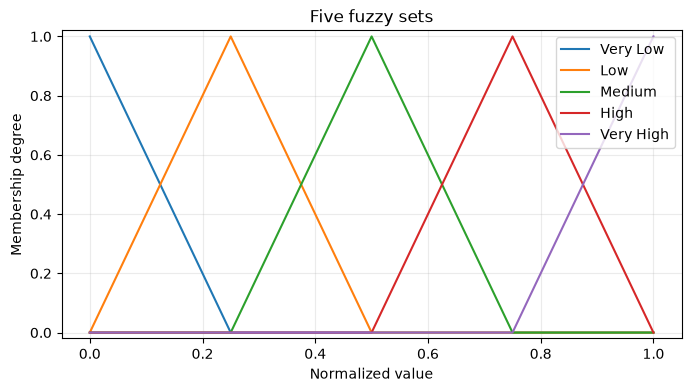

Memberships at x=0.80: {'Very Low': np.float64(0.0), 'Low': np.float64(0.0), 'Medium': np.float64(0.0), 'High': np.float64(0.8), 'Very High': np.float64(0.2)}


In [15]:
LINGUISTIC_LABELS = ["Very Low", "Low", "Medium", "High", "Very High"]
CENTRES = np.array([0.0, 0.25, 0.50, 0.75, 1.0])

def five_set_memberships(x):
    """Five overlapping fuzzy sets on [0,1], with shoulder sets at both ends."""
    x = float(np.clip(x, 0.0, 1.0))
    memberships = np.zeros(5, dtype=float)
    # Left shoulder: 1 at 0, decreasing to 0 at 0.25
    memberships[0] = max(0.0, (0.25 - x) / 0.25) if x <= 0.25 else 0.0
    # Three interior triangular sets
    for j in (1, 2, 3):
        left, centre, right = CENTRES[j-1], CENTRES[j], CENTRES[j+1]
        memberships[j] = max(0.0, min((x-left)/(centre-left), (right-x)/(right-centre)))
    # Right shoulder: increasing from 0.75 to 1
    memberships[4] = max(0.0, (x - 0.75) / 0.25) if x >= 0.75 else 0.0
    total = memberships.sum()
    return memberships / total if total else memberships

def fuzzy_similarity(user_value, destination_value):
    """1 - half the L1 distance between two five-set membership vectors."""
    mu_u = five_set_memberships(user_value)
    mu_d = five_set_memberships(destination_value)
    return float(1.0 - 0.5 * np.abs(mu_u - mu_d).sum())

# Visualize the five membership functions.
x_grid = np.linspace(0, 1, 301)
membership_curves = np.array([five_set_memberships(x) for x in x_grid])
plt.figure(figsize=(8, 4))
for j, label in enumerate(LINGUISTIC_LABELS):
    plt.plot(x_grid, membership_curves[:, j], label=label)
plt.xlabel("Normalized value")
plt.ylabel("Membership degree")
plt.title("Five fuzzy sets")
plt.ylim(-0.02, 1.02)
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Memberships at x=0.80:", dict(zip(LINGUISTIC_LABELS, five_set_memberships(0.80).round(3))))


## 5. Matching functions

The numerical matching function compares five-set fuzzy membership vectors.

For categorical variables, use explicit compatibility rules rather than forcing categories onto an arbitrary numeric scale:
- exact climate match = 1;
- adjacent climate category = 0.5;
- more distant climate category = 0;
- no preference = 1 (the criterion does not penalize any city).

For landscapes, calculate the fraction of the user's selected landscape types that the destination offers. This is a simple first version; later, users could assign different preference strengths to each landscape type.


In [16]:
CLIMATE_ORDER = ["Cold", "Cool", "Mild", "Warm", "Hot"]

def climate_compatibility(user_climate, destination_row):
    if user_climate is None or pd.isna(user_climate) or user_climate == "No preference":
        return 1.0
    destination_categories = [
        c for c in CLIMATE_ORDER
        if int(destination_row.get(f"climate_{c.lower()}", 0)) == 1
    ]
    if not destination_categories:
        return np.nan
    distances = [abs(CLIMATE_ORDER.index(user_climate) - CLIMATE_ORDER.index(c))
                 for c in destination_categories]
    d = min(distances)
    return {0: 1.0, 1: 0.5}.get(d, 0.0)

def landscape_compatibility(user_landscapes, destination_row):
    if not user_landscapes:
        return 1.0
    matched = sum(
        int(destination_row.get(f"landscape_{land.lower()}", 0)) == 1
        for land in user_landscapes
    )
    return matched / len(user_landscapes)

def numeric_user_value(user, topic):
    """Return profile/trip values for the numeric matching topics."""
    p = user["profile"]
    t = user["trip"]
    if topic == "food":
        return p.get("food")
    if topic == "authenticity":
        # A simple mapping of the categorical profile response to a 0..1
        # destination-authenticity preference. This mapping is a modelling assumption.
        mapping = {
            "Tourist-oriented experiences": 0.20,
            "Combination of both": 0.50,
            "Everyday local life": 0.90
        }
        return mapping.get(p.get("authenticity"))
    if topic == "relaxation":
        return p.get("relaxation"), t.get("relaxation")
    if topic == "unique":
        return p.get("unique"), t.get("unique")
    if topic == "travel_pace":
        return p.get("travel_pace"), t.get("travel_pace")
    if topic == "accommodation":
        return p.get("accommodation"), t.get("accommodation")
    if topic == "physical_activity":
        return p.get("physical_activity"), t.get("physical_activity")
    if topic == "safety":
        # Importance is a weight/priority, not a desired safety level.
        # Here we use it to scale the safety criterion's importance.
        return None
    if topic == "eco":
        return p.get("eco_importance")
    return None

def destination_numeric_score(row, topic):
    column = NUMERIC_CRITERIA[topic][0]
    return float(row[column])


## 6. Build criterion-level compatibility scores

A modelling note: some questionnaire answers represent **importance** rather than a desired level. Importance should normally influence the criterion weight, not be compared as if it were a target value. In this prototype:
- `landscape_importance` increases the landscape criterion weight;
- `safety_importance` increases the safety criterion weight;
- climate and landscape are handled as categories;
- the remaining numerical answers are treated as target preferences on [0,1].

The profile/trip 30/70 blend is applied to overlapping target-preference topics. Topics with only a profile answer use the profile result.


In [17]:
def get_user_destination_criteria(user, row):
    p, t = user["profile"], user["trip"]
    scores = {}

    # Profile-only numeric preference criteria
    for topic in ["food", "authenticity", "eco"]:
        user_val = numeric_user_value(user, topic)
        if user_val is not None:
            scores[topic] = fuzzy_similarity(user_val, destination_numeric_score(row, topic))

    # Both profile and trip preferences: 30% profile, 70% trip
    for topic in ["relaxation", "unique", "travel_pace", "accommodation", "physical_activity"]:
        p_val, t_val = numeric_user_value(user, topic)
        dest_val = destination_numeric_score(row, topic)
        c_p = fuzzy_similarity(p_val, dest_val)
        c_t = fuzzy_similarity(t_val, dest_val)
        scores[topic] = 0.30 * c_p + 0.70 * c_t

    # Landscape: importance determines criterion weight; selected categories determine match.
    scores["landscape"] = landscape_compatibility(
        t.get("landscapes", []), row
    )

    # Climate category match
    scores["climate"] = climate_compatibility(t.get("climate"), row)

    # Safety: importance affects weight, while destination safety is matched to a
    # neutral high-safety target. This is a temporary explicit assumption.
    scores["safety"] = float(row["safety"])

    return scores

def get_user_criterion_weights(user):
    weights = CRITERION_WEIGHTS.copy()
    # Importance answers scale the relevant weights (not the destination target).
    weights["landscape"] *= max(0.05, user["profile"].get("landscape_importance", 0.5))
    weights["safety"] *= max(0.05, user["profile"].get("safety_importance", 0.5))
    return weights

def criterion_score_table(user, destination_df):
    records = []
    for _, row in destination_df.iterrows():
        scores = get_user_destination_criteria(user, row)
        rec = {"destination_id": row["destination_id"], "city": row["city"], "country": row["country"]}
        rec.update(scores)
        records.append(rec)
    return pd.DataFrame(records)

alex_criteria = criterion_score_table(users["Alex"], destinations)
display(alex_criteria.head().round(3))


,destination_id,city,country,food,authenticity,eco,relaxation,unique,travel_pace,accommodation,physical_activity,landscape,climate,safety
0,EU001,Vienna,Austria,1.00,0.68,0.80,0.072,0.976,0.112,0.296,0.288,0.0,0.5,0.80
1,EU002,Salzburg,Austria,0.68,0.64,0.00,0.560,0.000,0.216,0.888,0.228,1.0,0.5,0.93
2,EU003,Brussels,Belgium,1.00,0.00,0.32,0.180,0.816,0.252,0.240,0.252,0.0,0.5,0.88
3,EU004,Bruges,Belgium,0.52,0.40,0.72,0.560,0.040,0.084,0.820,0.588,0.0,0.5,0.73
4,EU005,Dubrovnik,Croatia,0.52,0.40,0.60,0.156,0.656,0.000,0.456,0.204,0.0,1.0,0.73


## 7. Hard constraints and aggregation comparison

The strict maximum budget is applied before either aggregation method. Cities whose estimated total trip cost exceeds the user's maximum budget are marked ineligible.

The cost estimate is:

\[
\widehat{Cost}=DailyCost\times Days\times Travellers
\]

This simple multiplication is intentionally conservative and not a realistic travel quote. A better cost model could use per-person daily costs, shared room assumptions, flights, seasonality and uncertainty ranges.

After filtering, compare:
1. weighted arithmetic mean;
2. weighted geometric mean.

Both use the same criterion scores and weights, so differences in rankings come from the aggregation operator.


In [18]:
def aggregate_wam(score_values, weights):
    values = np.asarray(score_values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    valid = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    if not valid.any():
        return np.nan
    return float(np.average(values[valid], weights=weights[valid]))

def aggregate_wgm(score_values, weights, epsilon=1e-9):
    values = np.asarray(score_values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    valid = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    if not valid.any():
        return np.nan
    values = np.clip(values[valid], epsilon, 1.0)
    weights = weights[valid]
    normalized_weights = weights / weights.sum()
    return float(np.exp(np.sum(normalized_weights * np.log(values))))

def recommend(user_name, user, destination_df):
    weights_dict = get_user_criterion_weights(user)
    criterion_cols = list(weights_dict)
    criteria = criterion_score_table(user, destination_df)

    # Calculate estimated trip budget and strict eligibility.
    cost = destination_df[["destination_id", "daily_cost_eur_estimate"]].copy()
    cost["estimated_trip_cost_eur"] = (
        cost["daily_cost_eur_estimate"]
        * user["trip"]["duration_days"]
        * user["trip"]["travellers"]
    )
    cost["eligible"] = cost["estimated_trip_cost_eur"] <= user["trip"]["maximum_budget"]

    result = criteria.merge(cost[["destination_id", "estimated_trip_cost_eur", "eligible"]],
                            on="destination_id", how="left")
    weight_values = [weights_dict[c] for c in criterion_cols]

    result["WAM_score"] = result.apply(
        lambda r: aggregate_wam([r[c] for c in criterion_cols], weight_values), axis=1
    )
    result["WGM_score"] = result.apply(
        lambda r: aggregate_wgm([r[c] for c in criterion_cols], weight_values), axis=1
    )

    # Exclude destinations failing the strict maximum budget.
    eligible = result[result["eligible"]].copy()
    eligible["WAM_rank"] = eligible["WAM_score"].rank(ascending=False, method="min").astype(int)
    eligible["WGM_rank"] = eligible["WGM_score"].rank(ascending=False, method="min").astype(int)
    return result, eligible.sort_values("WAM_score", ascending=False), eligible.sort_values("WGM_score", ascending=False)

results = {}
for name, user in users.items():
    all_scores, wam_ranked, wgm_ranked = recommend(name, user, destinations)
    results[name] = {"all": all_scores, "wam": wam_ranked, "wgm": wgm_ranked}
    print(f"\n{name}: eligible {len(wam_ranked)} / {len(destinations)} destinations")
    print("Top 5 — weighted arithmetic mean")
    display(wam_ranked[["city","country","estimated_trip_cost_eur","WAM_score","WAM_rank"]].head().round(3))
    print("Top 5 — weighted geometric mean")
    display(wgm_ranked[["city","country","estimated_trip_cost_eur","WGM_score","WGM_rank"]].head().round(3))



Alex: eligible 17 / 50 destinations
Top 5 — weighted arithmetic mean


,city,country,estimated_trip_cost_eur,WAM_score,WAM_rank
46,Istanbul,Turkey,2300,0.564,1
19,Thessaloniki,Greece,2100,0.563,2
38,Ljubljana,Slovenia,1820,0.552,3
35,Porto,Portugal,2300,0.545,4
41,Seville,Spain,2500,0.526,5


Top 5 — weighted geometric mean


,city,country,estimated_trip_cost_eur,WGM_score,WGM_rank
38,Ljubljana,Slovenia,1820,0.480,1
37,Brasov,Romania,1800,0.132,2
39,Maribor,Slovenia,2000,0.078,3
46,Istanbul,Turkey,2300,0.068,4
32,Krakow,Poland,2000,0.060,5



Blair: eligible 48 / 50 destinations
Top 5 — weighted arithmetic mean


,city,country,estimated_trip_cost_eur,WAM_score,WAM_rank
32,Krakow,Poland,700,0.653,1
15,Lyon,France,1498,0.650,2
39,Maribor,Slovenia,700,0.618,3
3,Bruges,Belgium,1015,0.575,4
17,Munich,Germany,959,0.560,5


... (14 outputs left out)


Culture Enthusiast: eligible 50 / 50 destinations
Top 5 — weighted arithmetic mean


,city,country,estimated_trip_cost_eur,WAM_score,WAM_rank
2,Brussels,Belgium,2170,0.692,1
48,London,United Kingdom,3080,0.677,2
46,Istanbul,Turkey,1610,0.658,3
45,Lucerne,Switzerland,2870,0.653,4
25,Galway,Ireland,2170,0.615,5


Top 5 — weighted geometric mean


,city,country,estimated_trip_cost_eur,WGM_score,WGM_rank
4,Dubrovnik,Croatia,2450,0.365,1
0,Vienna,Austria,2310,0.332,2
48,London,United Kingdom,3080,0.193,3
37,Brasov,Romania,1260,0.134,4
2,Brussels,Belgium,2170,0.130,5


## 8. Compare the two aggregation methods

The next table compares the top results for each artificial user. The rankings may differ because the geometric mean penalizes a very weak criterion more strongly than the arithmetic mean.

A high score should not be interpreted as a real-world quality judgement while destination values remain synthetic.


In [19]:
for name in users:
    wam = results[name]["wam"][["city","WAM_score","WAM_rank"]].head(5).copy()
    wgm = results[name]["wgm"][["city","WGM_score","WGM_rank"]].head(5).copy()
    comparison = wam.merge(wgm, on="city", how="outer", suffixes=("_WAM","_WGM"))
    print(f"\n{name} — top-five comparison")
    display(comparison.round(3))


# Quantitative comparison of WAM and WGM rankings.
# Calculate Spearman correlation from ranked values using NumPy/Pandas only.
# This avoids requiring SciPy in the user's Python environment.
comparison_summary = []
for name in users:
    wam_order = results[name]["wam"].set_index("city")["WAM_rank"]
    wgm_order = results[name]["wgm"].set_index("city")["WGM_rank"]
    common = wam_order.index.intersection(wgm_order.index)

    if len(common) > 1:
        wam_ranks = wam_order.loc[common].rank(method="average").to_numpy(dtype=float)
        wgm_ranks = wgm_order.loc[common].rank(method="average").to_numpy(dtype=float)
        rho = float(np.corrcoef(wam_ranks, wgm_ranks)[0, 1])
    else:
        rho = np.nan

    top_wam = set(results[name]["wam"].head(5)["city"])
    top_wgm = set(results[name]["wgm"].head(5)["city"])
    comparison_summary.append({
        "user": name,
        "top5_shared_destinations": len(top_wam & top_wgm),
        "top5_overlap_percent": 100 * len(top_wam & top_wgm) / 5,
        "spearman_rank_correlation": rho
    })

aggregation_comparison = pd.DataFrame(comparison_summary)
print("Agreement between WAM and WGM (higher overlap/correlation means more similar rankings):")
display(aggregation_comparison.round(3))



Alex — top-five comparison


,city,WAM_score,WAM_rank,WGM_score,WGM_rank
0,Brasov,NaN,NaN,0.132,2.0
1,Istanbul,0.564,1.0,0.068,4.0
2,Krakow,NaN,NaN,0.060,5.0
3,Ljubljana,0.552,3.0,0.480,1.0
4,Maribor,NaN,NaN,0.078,3.0
5,Porto,0.545,4.0,NaN,NaN
6,Seville,0.526,5.0,NaN,NaN
7,Thessaloniki,0.563,2.0,NaN,NaN



Blair — top-five comparison


,city,WAM_score,WAM_rank,WGM_score,WGM_rank
0,Bruges,0.575,4.0,0.056,5.0
1,Florence,NaN,NaN,0.096,4.0
2,Krakow,0.653,1.0,0.132,2.0
3,Lyon,0.650,2.0,0.133,1.0
4,Maribor,0.618,3.0,NaN,NaN
5,Munich,0.560,5.0,NaN,NaN
6,Tartu,NaN,NaN,0.104,3.0



Casey — top-five comparison


,city,WAM_score,WAM_rank,WGM_score,WGM_rank
0,Antalya,0.279,3.0,0.000,5.0
1,Brasov,0.340,1.0,0.001,1.0
2,Budapest,NaN,NaN,0.000,3.0
3,Istanbul,0.286,2.0,0.000,2.0
4,Krakow,0.205,5.0,NaN,NaN
5,Ljubljana,0.209,4.0,NaN,NaN
6,Maribor,NaN,NaN,0.000,4.0


... (4 outputs left out)


Culture Enthusiast — top-five comparison


,city,WAM_score,WAM_rank,WGM_score,WGM_rank
0,Brasov,NaN,NaN,0.134,4.0
1,Brussels,0.692,1.0,0.130,5.0
2,Dubrovnik,NaN,NaN,0.365,1.0
3,Galway,0.615,5.0,NaN,NaN
4,Istanbul,0.658,3.0,NaN,NaN
5,London,0.677,2.0,0.193,3.0
6,Lucerne,0.653,4.0,NaN,NaN
7,Vienna,NaN,NaN,0.332,2.0


Agreement between WAM and WGM (higher overlap/correlation means more similar rankings):


,user,top5_shared_destinations,top5_overlap_percent,spearman_rank_correlation
0,Alex,2,40.0,0.429
1,Blair,3,60.0,0.855
2,Casey,3,60.0,0.650
3,Relaxation Seeker,2,40.0,0.703
4,Adventurer,1,20.0,0.833
5,Culture Enthusiast,2,40.0,0.516


## 9. Sensitivity analysis: change one answer at a time

This experiment starts from Alex's answers and changes one trip preference at a time, leaving all other answers unchanged. It tests whether the ranking responds to:

1. Relaxation preference (low vs high).
2. Desired landscape (mountains/lakes vs beaches).
3. Climate preference (cool vs hot).
4. Desired physical activity (low vs high).

The output reports the top five WAM destinations for each scenario and the number of destinations shared with the baseline top five. These are exploratory checks, not proof that a particular ranking is objectively correct.

In [20]:
from copy import deepcopy

def top_five_for_test(test_user):
    _, wam_ranked, _ = recommend("Sensitivity test", test_user, destinations)
    return wam_ranked.head(5)[["city", "WAM_score"]].reset_index(drop=True)

baseline_user = deepcopy(users["Alex"])
baseline_top5 = top_five_for_test(baseline_user)
baseline_set = set(baseline_top5["city"])

sensitivity_scenarios = {
    "Baseline (Alex)": baseline_user,
}

test_user = deepcopy(baseline_user)
test_user["trip"]["relaxation"] = 0.10
sensitivity_scenarios["Low relaxation"] = test_user

test_user = deepcopy(baseline_user)
test_user["trip"]["relaxation"] = 0.95
sensitivity_scenarios["High relaxation"] = test_user

test_user = deepcopy(baseline_user)
test_user["trip"]["landscapes"] = ["Beaches"]
sensitivity_scenarios["Beach preference"] = test_user

test_user = deepcopy(baseline_user)
test_user["trip"]["landscapes"] = ["Mountains", "Lakes"]
sensitivity_scenarios["Mountain/lake preference"] = test_user

test_user = deepcopy(baseline_user)
test_user["trip"]["climate"] = "Cool"
sensitivity_scenarios["Cool climate"] = test_user

test_user = deepcopy(baseline_user)
test_user["trip"]["climate"] = "Hot"
sensitivity_scenarios["Hot climate"] = test_user

test_user = deepcopy(baseline_user)
test_user["trip"]["physical_activity"] = 0.10
sensitivity_scenarios["Low physical activity"] = test_user

test_user = deepcopy(baseline_user)
test_user["trip"]["physical_activity"] = 0.95
sensitivity_scenarios["High physical activity"] = test_user

sensitivity_rows = []
for scenario_name, test_user in sensitivity_scenarios.items():
    top5 = top_five_for_test(test_user)
    top_set = set(top5["city"])
    sensitivity_rows.append({
        "scenario": scenario_name,
        "top_5_destinations": ", ".join(top5["city"].tolist()),
        "destinations_shared_with_baseline": len(top_set & baseline_set)
    })

sensitivity_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_results)


,scenario,top_5_destinations,destinations_shared_with_baseline
0,Baseline (Alex),"Istanbul, Thessaloniki, Ljubljana, Porto, Seville",5
1,Low relaxation,"Brasov, Thessaloniki, Istanbul, Ljubljana, Porto",4
2,High relaxation,"Thessaloniki, Istanbul, Ljubljana, Brasov, Porto",4
3,Beach preference,"Istanbul, Thessaloniki, Porto, Lisbon, Antalya",3
4,Mountain/lake preference,"Istanbul, Thessaloniki, Ljubljana, Porto, Seville",5
5,Cool climate,"Ljubljana, Tallinn, Brasov, Krakow, Turku",1
6,Hot climate,"Seville, Istanbul, Thessaloniki, Brasov, Ljubl...",4
7,Low physical activity,"Thessaloniki, Istanbul, Ljubljana, Porto, Seville",5
8,High physical activity,"Thessaloniki, Ljubljana, Brasov, Istanbul, Sev...",4


## 10. Inspect one destination's explanation

A recommender should be explainable. This cell displays the criterion scores for a selected user and city, alongside the final WAM and WGM scores.

Low criterion compatibility values show where a destination does not fit the user's answers. In a later version, we can generate natural-language explanations such as “good landscape match, but weak climate match”.


In [21]:
def explain_destination(user_name, city_name):
    user = users[user_name]
    all_scores, wam_ranked, wgm_ranked = recommend(user_name, user, destinations)
    row = all_scores.loc[all_scores["city"].eq(city_name)].iloc[0]
    weights = get_user_criterion_weights(user)
    detail = pd.DataFrame({
        "criterion": list(weights.keys()),
        "compatibility": [row[k] for k in weights],
        "weight": [weights[k] for k in weights],
    })
    detail["weighted_contribution_WAM"] = detail["compatibility"] * detail["weight"]
    display(detail.sort_values("weighted_contribution_WAM", ascending=False).round(3))
    print("Eligible under maximum budget:", bool(row["eligible"]))
    print("Estimated trip cost (€):", round(row["estimated_trip_cost_eur"], 2))
    print("WAM score:", round(row["WAM_score"], 3))
    print("WGM score:", round(row["WGM_score"], 3))

explain_destination("Alex", "Lisbon")


,criterion,compatibility,weight,weighted_contribution_WAM
9,climate,1.000,1.500,1.500
8,safety,0.920,1.245,1.145
0,food,1.000,1.000,1.000
2,relaxation,0.564,1.500,0.846
3,unique,0.560,1.000,0.560
1,authenticity,0.520,1.000,0.520
6,accommodation,0.336,1.500,0.504
7,physical_activity,0.288,1.000,0.288
5,travel_pace,0.120,1.000,0.120
4,landscape,0.000,1.350,0.000


Eligible under maximum budget: True
Estimated trip cost (€): 2500
WAM score: 0.507
WGM score: 0.021


## 11. Model limitations and next improvements

Before treating this as the final academic model, address these points:

1. **Destination data quality:** replace every synthetic placeholder with sourced observations and a written scoring rubric. Record source, date, season, unit and confidence for each value.
2. **Meaning of each questionnaire answer:** preference, importance, comfort, and constraint are different constructs. Importance should usually modify a weight; it should not be compared directly with a destination attribute.
3. **Directionality:** “comfort with limited infrastructure” is not the same as “infrastructure quality required”. Define a meaningful transformation or a separate destination-side variable.
4. **Profile/trip balance:** the 30/70 rule currently applies to selected overlapping target-preference criteria. Validate it with sensitivity tests; it need not apply to every topic.
5. **Categorical criteria:** climate and landscapes currently use simple compatibility rules. More detailed fuzzy categorical preferences could be added.
6. **Missing values:** missing destination data should remain missing and be handled explicitly. Do not interpret missing as zero.
7. **Weights:** the current weights are provisional. Derive them from your questionnaire priorities, expert judgement, user-stated importance or a sensitivity analysis, and justify the choice.
8. **Budget model:** include transport to the destination, accommodation assumptions, trip season and group size if the maximum budget is a strict constraint.
9. **Avoid double counting:** correlated criteria (e.g. landscape quality and landscape preference; activity opportunities and travel pace) may overemphasize one aspect.
10. **Evaluation:** test whether plausible changes in user answers lead to understandable changes in rankings. Compare WAM and WGM rankings, and perform sensitivity analysis on weights and the 30/70 balance.

This prototype uses fuzzy sets to represent and compare graded preferences, followed by two alternative aggregation operators. It is a valid starting architecture, but it is not yet a complete fuzzy inference system with an IF–THEN rule base. That distinction should be made clear in the project report.
